# EDA OF THE CUSTOMER CHURN PROJECT

## 1. DATA INSPECTION

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
churn_df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
churn_df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


### Initial dataset inspection

In [3]:
churn_df.shape

(7043, 21)

In [4]:
churn_df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [5]:
churn_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Data Dictionary

1. Customer Demographics

| Variable | Description | Possible Values |
|---|---|---|
| `customerID` | Unique identifier assigned to each customer. | Unique ID |
| `gender` | Gender of the customer. | Male, Female |
| `SeniorCitizen` | Indicates whether the customer is a senior citizen. | 0 = No, 1 = Yes |
| `Partner` | Indicates whether the customer has a partner. | Yes, No |
| `Dependents` | Indicates whether the customer has dependents. | Yes, No |

2. Customer Account Information

| Variable | Description | Possible Values |
|---|---|---|
| `tenure` | Number of months the customer has remained with the company. | Numerical |
| `Contract` | Type of contractual agreement. | Month-to-month, One year, Two year |
| `PaperlessBilling` | Indicates whether the customer receives paperless bills. | Yes, No |
| `PaymentMethod` | Payment method used by the customer. | Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic) |
| `MonthlyCharges` | Amount charged to the customer monthly. | Numerical |
| `TotalCharges` | Cumulative amount charged to the customer throughout their relationship with the company. | Numerical |

3. Telecommunications Services

| Variable | Description | Possible Values |
|---|---|---|
| `PhoneService` | Indicates whether the customer subscribes to phone services. | Yes, No |
| `MultipleLines` | Indicates whether the customer has multiple telephone lines. | Yes, No, No phone service |
| `InternetService` | Type of internet connection subscribed to. | DSL, Fiber optic, No |
| `OnlineSecurity` | Indicates whether the customer subscribes to online security services. | Yes, No, No internet service |
| `OnlineBackup` | Indicates whether the customer subscribes to online backup services. | Yes, No, No internet service |
| `DeviceProtection` | Indicates whether the customer subscribes to device protection services. | Yes, No, No internet service |
| `TechSupport` | Indicates whether the customer subscribes to technical support services. | Yes, No, No internet service |
| `StreamingTV` | Indicates whether the customer subscribes to television streaming services. | Yes, No, No internet service |
| `StreamingMovies` | Indicates whether the customer subscribes to movie streaming services. | Yes, No, No internet service |

4. Target Variable

| Variable | Description | Possible Values |
|---|---|---|
| `Churn` | Indicates whether the customer discontinued their telecommunications services. | Yes, No |

For modelling purposes:
- `1` = Customer churned.
- `0` = Customer did not churn.

 5. Variable Classification

| Data Type | Variables |
|---|---|
| Identifier | `customerID` |
| Binary categorical | `gender`, `Partner`, `Dependents`, `PaperlessBilling`, `PhoneService` |
| Multiclass categorical | `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaymentMethod` |
| Numerical | `tenure`, `MonthlyCharges`, `TotalCharges` |
| Binary numerical | `SeniorCitizen` |
| Target | `Churn` |



### Data qualtiy assessments

In [6]:
churn_df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
churn_df.duplicated().sum()

np.int64(0)

In [8]:
churn_df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Convert to the right data type

In [9]:
churn_df["TotalCharges"]=pd.to_numeric(churn_df["TotalCharges"],errors='coerce')
churn_df["TotalCharges"].dtype

dtype('float64')

In [10]:
display(churn_df[churn_df["TotalCharges"].isnull()])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Following the conversion of TotalCharges from object to numeric data type, 11 missing values were identified. These values were initially represented as blank or whitespace entries, which were not necessarily recognized as missing by Pandas. Further investigation revealed that the affected records correspond to customers with zero tenure, suggesting that the missing cumulative charges may be associated with newly registered customers.

### Inspect target

In [11]:
churn_df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [12]:
churn_df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

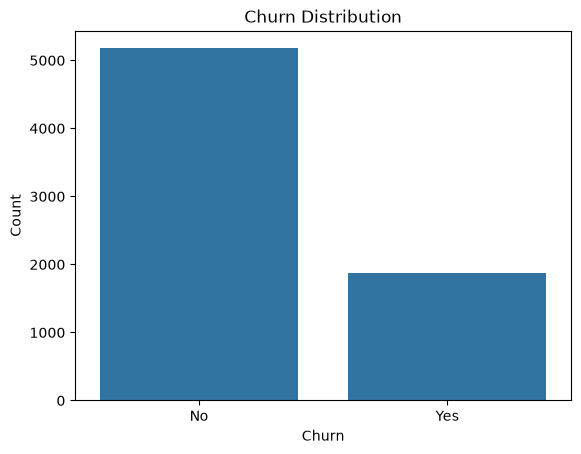

In [13]:
sns.countplot(data=churn_df, x='Churn')

plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

### Conclusion

The dataset contains 7,043 customer records and 21 variables, with no duplicate rows or missing values detected initially. Converting TotalCharges to numeric revealed 11 blank values, all associated with customers who have zero tenure, so these should be handled during preprocessing. About 26.5% of customers churned, compared with 73.5% who stayed, indicating a class imbalance to consider during model development.

## 2. EXPLORATORY DATA ANALYSIS

Questions to explore

1. How does churn vary across contract types, and does the relationship differ by customer tenure?
2. Are customers with higher monthly charges more likely to churn, especially among month-to-month customers?
3. How do tenure and total charges relate to churn? Are newer customers more likely to leave?
4. Does churn differ by internet service type, and is it associated with having online security or tech support?
5. Are customers who use electronic checks more likely to churn than those using automatic payment methods?
6. Do customers with multiple services, such as phone and internet, churn at different rates from customers with fewer services?
7. How do partner or dependent status relate to tenure and churn?
8. Does churn vary by senior-citizen status, and does contract type change that pattern?
9. Are paperless billing and payment method related, and how do those combinations relate to churn?


In [14]:
from scipy import stats

churn_df["Churn"] = churn_df["Churn"].map({"No": 0, "Yes": 1})

# Fill missing TotalCharges with MonthlyCharges * tenure
churn_df["TotalCharges"] = churn_df["TotalCharges"].fillna(churn_df["MonthlyCharges"] * churn_df["tenure"])

# Tenure band used for many analyses
churn_df["tenure_band"] = pd.cut(
    churn_df["tenure"],
    bins=[0, 12, 24, 36, 48, 60, 120],
    labels=["0-12", "13-24", "25-36", "37-48", "49-60", "60+"],
    include_lowest=True
)

sns.set_theme(style="whitegrid", context="talk")

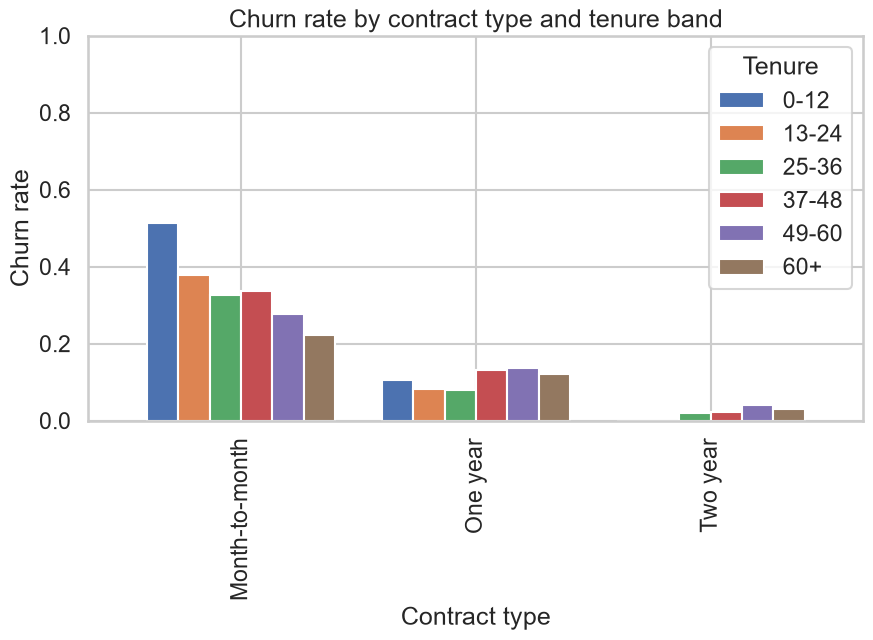

Chi-square: 1184.60, p-value: 5.863e-258


In [16]:
# 1. How does churn vary across contract types, and does the relationship differ by customer tenure?

summary = (
    churn_df.groupby(["Contract", "tenure_band"], as_index=False)["Churn"]
      .mean()
      .pivot(index="Contract", columns="tenure_band", values="Churn")
)

fig, ax = plt.subplots(figsize=(10, 5))
summary.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Churn rate by contract type and tenure band")
ax.set_xlabel("Contract type")
ax.set_ylabel("Churn rate")
ax.set_ylim(0, 1)
ax.legend(title="Tenure")
plt.show()

chi2, p_value, _, _ = stats.chi2_contingency(pd.crosstab(churn_df["Contract"], churn_df["Churn"]))
print(f"Chi-square: {chi2:.2f}, p-value: {p_value:.3e}")

**Interpretation:** Month-to-month customers have the highest churn, especially during their first 12 months (about 51%). Churn is much lower for one-year contracts (roughly 8?14%) and two-year contracts (roughly 0?4%) across the tenure bands. The chi-square result (?? = 1184.60, p < 0.001) indicates a strong association between contract type and churn. In telecom terms, customers without a long-term commitment?particularly newer customers?are the most at risk, so early retention and suitable longer-term offers may help. This is an association, not proof that contract length alone causes retention.

C:\Users\hp\AppData\Local\Temp\ipykernel_3844\8254492.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed", "Churned"])


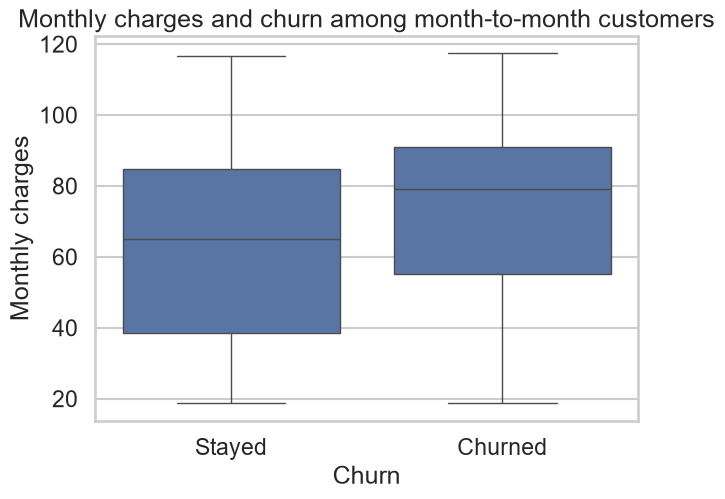

Welch t-test: t=-13.81, p=2.288e-42


In [18]:
#2. Are customers with higher monthly charges more likely to churn, especially among month-to-month customers?

month_to_month = churn_df[churn_df["Contract"] == "Month-to-month"].copy()

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=month_to_month, x="Churn", y="MonthlyCharges", ax=ax)
ax.set_title("Monthly charges and churn among month-to-month customers")
ax.set_xlabel("Churn")
ax.set_ylabel("Monthly charges")
ax.set_xticklabels(["Stayed", "Churned"])
plt.show()

x = month_to_month[month_to_month["Churn"] == 0]["MonthlyCharges"]
y = month_to_month[month_to_month["Churn"] == 1]["MonthlyCharges"]

t_stat, p_value = stats.ttest_ind(x, y, equal_var=False)
print(f"Welch t-test: t={t_stat:.2f}, p={p_value:.3e}")

**Interpretation:** Among month-to-month customers, mean monthly charges are about $73.02 for customers who churned and $61.46 for those who stayed. The Welch test (t = ?13.81, p < 0.001) supports a difference in average charges. Higher bills may contribute to perceived value concerns in this flexible-contract group; review plan fit and bill clarity before treating price as the cause.

C:\Users\hp\AppData\Local\Temp\ipykernel_3844\1872562722.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Stayed", "Churned"])
C:\Users\hp\AppData\Local\Temp\ipykernel_3844\1872562722.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Stayed", "Churned"])


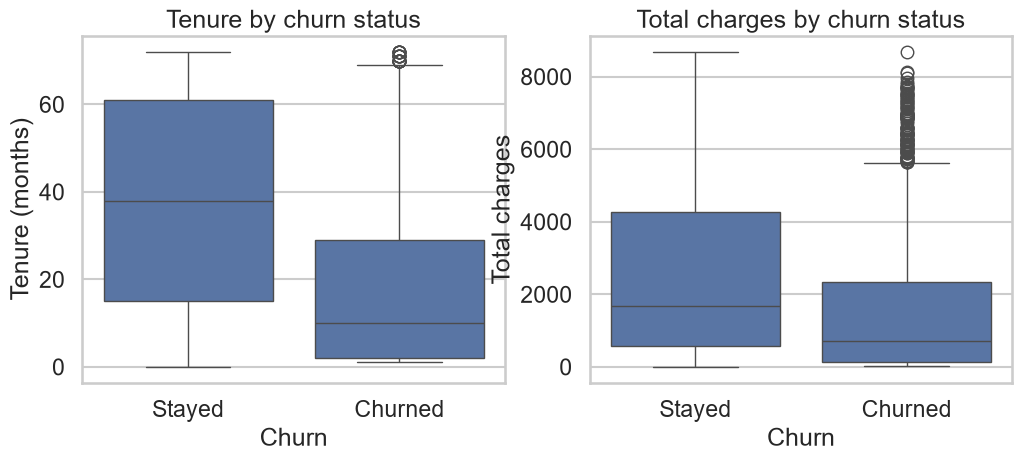

Tenure difference: t=34.82, p=1.195e-232
TotalCharges difference: t=18.71, p=5.903e-75


In [19]:
#3. How do tenure and total charges relate to churn? Are newer customers more likely to leave?

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=churn_df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by churn status")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")
axes[0].set_xticklabels(["Stayed", "Churned"])

sns.boxplot(data=churn_df, x="Churn", y="TotalCharges", ax=axes[1])
axes[1].set_title("Total charges by churn status")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Total charges")
axes[1].set_xticklabels(["Stayed", "Churned"])
plt.show()

tenure_stayed = churn_df[churn_df["Churn"] == 0]["tenure"]
tenure_churned = churn_df[churn_df["Churn"] == 1]["tenure"]

total_stayed = churn_df[churn_df["Churn"] == 0]["TotalCharges"]
total_churned = churn_df[churn_df["Churn"] == 1]["TotalCharges"]

tenure_t, tenure_p = stats.ttest_ind(tenure_stayed, tenure_churned, equal_var=False)
total_t, total_p = stats.ttest_ind(total_stayed, total_churned, equal_var=False)

print(f"Tenure difference: t={tenure_t:.2f}, p={tenure_p:.3e}")
print(f"TotalCharges difference: t={total_t:.2f}, p={total_p:.3e}")

**Interpretation:** Customers who churned had an average tenure of about 18 months versus 38 months for those who stayed, and average total charges of about $1,532 versus $2,550. Both differences are statistically significant (p < 0.001). This points to an early-relationship retention challenge. Lower total charges likely reflect shorter time as a customer as well as spending, so they should not be read as evidence that lower prices cause churn.

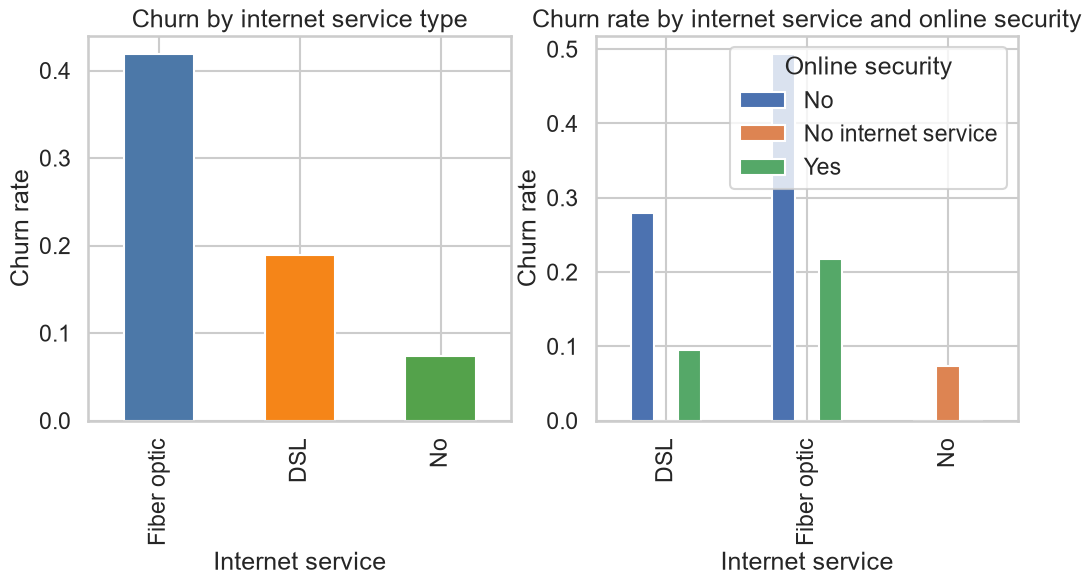

InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64


In [20]:
#4. Does churn differ by internet service type, and is it associated with having online security or tech support?

# Internet service rate
internet_rates = churn_df.groupby("InternetService")["Churn"].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

internet_rates.plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518", "#54A24B"])
axes[0].set_title("Churn by internet service type")
axes[0].set_xlabel("Internet service")
axes[0].set_ylabel("Churn rate")

support = (
    churn_df.groupby(["InternetService", "OnlineSecurity"], as_index=False)["Churn"]
      .mean()
      .pivot(index="InternetService", columns="OnlineSecurity", values="Churn")
)

support.plot(kind="bar", ax=axes[1])
axes[1].set_title("Churn rate by internet service and online security")
axes[1].set_xlabel("Internet service")
axes[1].set_ylabel("Churn rate")
axes[1].legend(title="Online security")
plt.show()

print(churn_df.groupby("InternetService")["Churn"].mean())

**Interpretation:** Churn is highest among fiber-optic customers (about 41.9%), compared with DSL (19.0%) and customers without internet service (7.4%). Within internet customers, churn is also higher when online security is absent (about 49.4% for fiber and 28.0% for DSL) than when it is present (21.8% and 9.5%, respectively). This suggests investigating fiber experience/value and offering relevant security support. This cell analyzes OnlineSecurity; it does not report a separate TechSupport result, despite the question mentioning it.

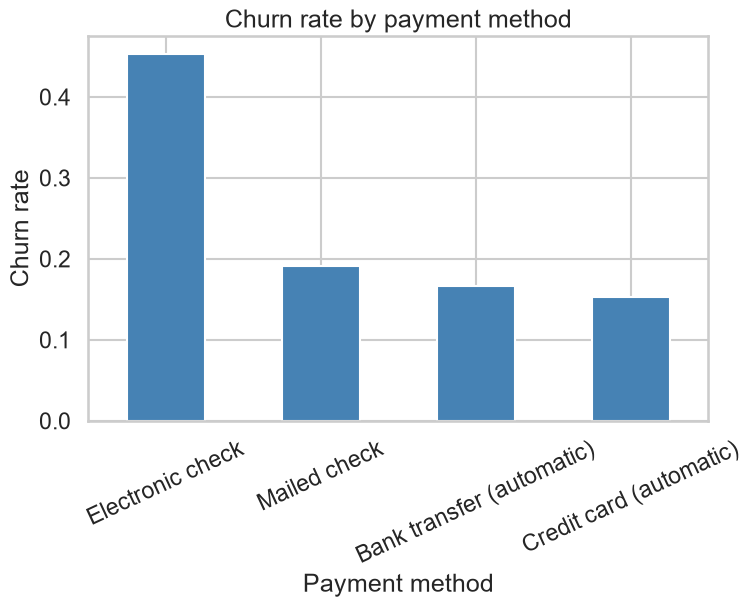

Payment method vs churn: chi-square=648.14, p=3.682e-140


In [21]:
#5. Are customers who use electronic checks more likely to churn than those using automatic payment methods?

payment_rates = churn_df.groupby("PaymentMethod")["Churn"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
payment_rates.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Churn rate by payment method")
ax.set_xlabel("Payment method")
ax.set_ylabel("Churn rate")
ax.tick_params(axis="x", rotation=25)
plt.show()

chi2, p_value, _, _ = stats.chi2_contingency(pd.crosstab(churn_df["PaymentMethod"], churn_df["Churn"]))
print(f"Payment method vs churn: chi-square={chi2:.2f}, p={p_value:.3e}")

**Interpretation:** Electronic-check customers have the highest churn rate (about 45.3%), compared with about 15?19% for the other payment methods. The chi-square result (?? = 648.14, p < 0.001) indicates payment method and churn are associated. This is a useful group for reviewing payment friction and customer experience, but it does not show that electronic checks themselves cause churn or justify removing that payment option.

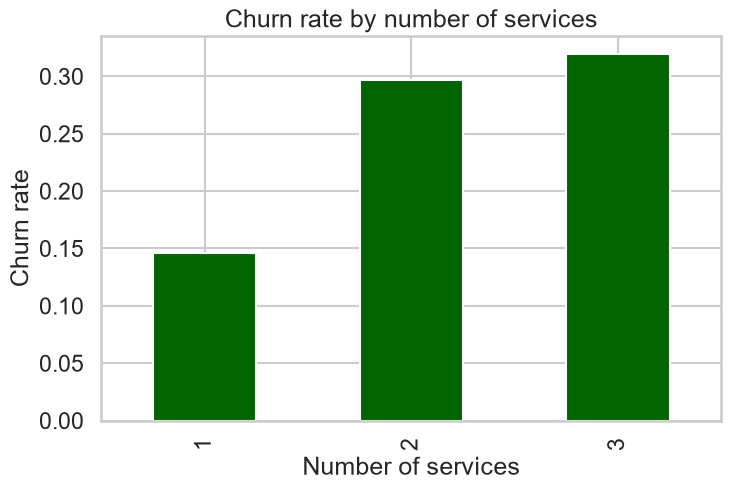

Correlation between service count and churn: r=0.148, p=7.892e-36


In [23]:
#6. Do customers with multiple services, such as phone and internet, churn at different rates from customers with fewer services?

# Create a basic service-count variable
service_count = (
    churn_df[["PhoneService", "InternetService", "MultipleLines"]]
      .replace({"Yes": 1, "No": 0, "No phone service": 0})
      .assign(
          InternetService=lambda x: x["InternetService"].replace({"DSL": 1, "Fiber optic": 1, "No": 0})
      )
      .sum(axis=1)
      .astype(int)
)

churn_df["service_count"] = service_count

grouped = churn_df.groupby("service_count")["Churn"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
grouped.plot(kind="bar", ax=ax, color="darkgreen")
ax.set_title("Churn rate by number of services")
ax.set_xlabel("Number of services")
ax.set_ylabel("Churn rate")
plt.show()

corr, p_value = stats.pearsonr(churn_df["service_count"], churn_df["Churn"])
print(f"Correlation between service count and churn: r={corr:.3f}, p={p_value:.3e}")

**Interpretation:** The constructed service-count measure has a positive, statistically significant correlation with churn (r = 0.148, p < 0.001); the plotted churn rate rises from about 14.6% at count 1 to 29.7% at count 2 and 32.0% at count 3. This does not support the assumption that more services are protective. Interpret cautiously: the measure counts PhoneService and MultipleLines separately, so it is a feature count rather than a count of distinct service categories. The result is a modest association, not evidence that adding services increases churn.

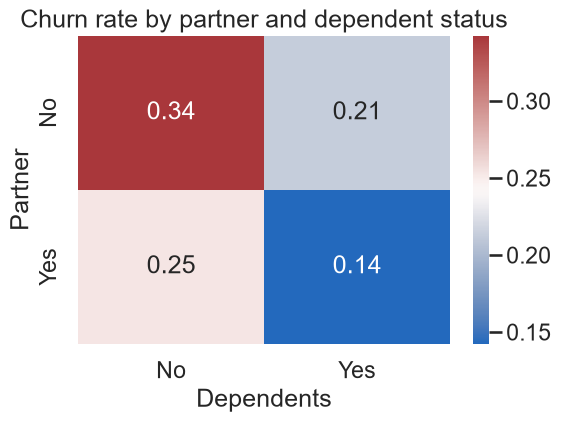

Dependents        No       Yes
Partner                       
No          0.342378  0.213296
Yes         0.254083  0.142367


In [24]:
#7. How do partner or dependent status relate to tenure and churn?

heat = (
    churn_df.groupby(["Partner", "Dependents"], as_index=False)["Churn"]
      .mean()
      .pivot(index="Partner", columns="Dependents", values="Churn")
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="vlag", ax=ax)
ax.set_title("Churn rate by partner and dependent status")
ax.set_xlabel("Dependents")
ax.set_ylabel("Partner")
plt.show()

print(heat)

**Interpretation:** Churn is highest among customers with neither a partner nor dependents (34.2%) and lowest among those with both (14.2%); the other groups are 21.3% and 25.4%. Household status may help segment retention outreach, but it should not be treated as a cause or as a basis for excluding customers from support. Although the question mentions tenure, this heatmap compares churn only and does not analyze tenure.

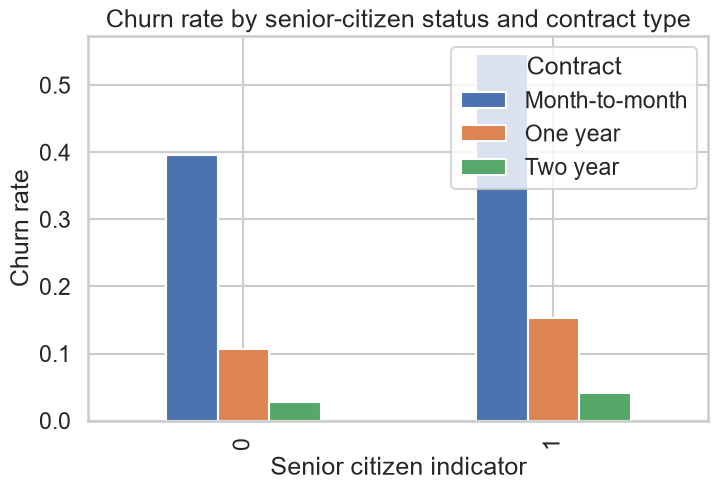

Contract       Month-to-month  One year  Two year
SeniorCitizen                                    
0                    0.395698  0.106781  0.027097
1                    0.546468  0.152632  0.041379


In [25]:
#8. Does churn vary by senior-citizen status, and does contract type change that pattern?

rates = (
    churn_df.groupby(["SeniorCitizen", "Contract"], as_index=False)["Churn"]
      .mean()
      .pivot(index="SeniorCitizen", columns="Contract", values="Churn")
)

fig, ax = plt.subplots(figsize=(8, 5))
rates.plot(kind="bar", ax=ax)
ax.set_title("Churn rate by senior-citizen status and contract type")
ax.set_xlabel("Senior citizen indicator")
ax.set_ylabel("Churn rate")
ax.legend(title="Contract")
plt.show()

print(rates)

**Interpretation:** Senior citizens have higher churn rates than non-seniors within each contract type: 54.6% versus 39.6% for month-to-month, 15.3% versus 10.7% for one-year, and 4.1% versus 2.7% for two-year contracts. Month-to-month is the highest-risk contract for both groups, while two-year contracts have the lowest churn. Retention efforts could prioritize senior customers on month-to-month plans with accessible, suitable alternatives; these grouped rates show association, not causation.

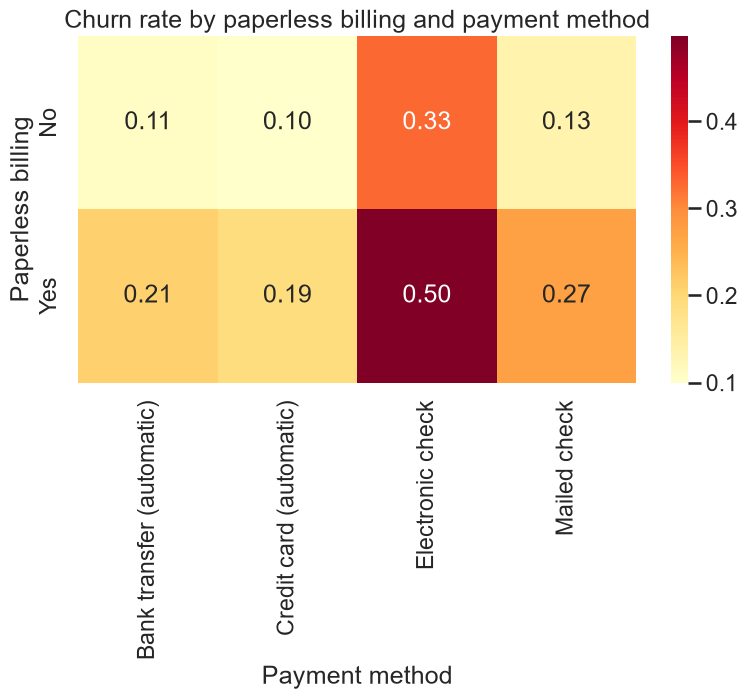

Combined payment/paperless relationship: chi-square=788.66, p=5.182e-166


In [26]:
#9. Are paperless billing and payment method related, and how do those combinations relate to churn?

combined = (
    churn_df.groupby(["PaperlessBilling", "PaymentMethod"], as_index=False)["Churn"]
      .mean()
      .pivot(index="PaperlessBilling", columns="PaymentMethod", values="Churn")
)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(combined, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax)
ax.set_title("Churn rate by paperless billing and payment method")
ax.set_xlabel("Payment method")
ax.set_ylabel("Paperless billing")
plt.show()

chi2, p_value, _, _ = stats.chi2_contingency(
    pd.crosstab([churn_df["PaperlessBilling"], churn_df["PaymentMethod"]], churn_df["Churn"])
)
print(f"Combined payment/paperless relationship: chi-square={chi2:.2f}, p={p_value:.3e}")

**Interpretation:** Electronic-check customers have the highest churn in both billing groups (49.8% with paperless billing; 32.7% without). For each listed payment method, churn is higher in the paperless group in this sample. The reported chi-square test (?? = 788.66, p < 0.001) tests whether churn differs across the combined billing/payment groups. It does not by itself test whether paperless billing and payment method are associated with each other, so that part of the question is not answered by this test.

## Overall conclusion

The clearest churn-risk patterns in these exploratory results are month-to-month contracts (particularly during the first year), higher monthly charges among month-to-month customers, fiber-optic service, absence of online security, electronic-check payment, and higher churn among senior customers within each contract type. Customers without a partner or dependents also have higher churn in the displayed groups. These are associations in this dataset, not proof of causes.

The results do **not** show that longer tenure or higher total charges increase churn: customers who left had shorter tenure and lower accumulated charges on average. Nor does this notebook support the assumption that a larger service bundle protects customers. The service-count measure is positively associated with churn, though it counts phone service and multiple lines separately and needs better definition. The low churn in longer contracts is a comparative pattern, not evidence that every customer should be pushed into a longer contract. Gender and other unplotted features are not evaluated here, so no conclusion that they do or do not matter is warranted.

**Recommended actions:** 
(1) strengthen onboarding and proactive check-ins during the first 12 months, especially for month-to-month customers; 
(2) review plan fit, bill clarity, and service quality for high-charge and fiber customers; 
(3) make online security and support easy to understand and adopt; 
(4) investigate payment friction among electronic-check users while preserving payment choice; 
(5) tailor accessible retention options for senior customers and use household status only as a respectful segmentation signal; and 
(6) test interventions with controlled experiments and monitor churn by segment before scaling. The exploratory comparisons should be followed by adjusted analysis that accounts for overlapping factors before attributing risk to any one feature.